# Taller 3 Técnicas de Aprendizaje de Máquina

In [1]:
!pip install scikit-learn
!pip install kagglehub
!pip install pandas 
!pip install numpy 
!pip install matplotlib 
!pip install seaborn 
!pip install plotly
# Estas toca instalarlas tambien en el terminal de la computadora, no solo en el notebook.

In [2]:
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import sklearn 

c:\Users\carlo\AppData\Local\Programs\Python\Python314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
# Download latest version
path = kagglehub.dataset_download("vjchoudhary7/customer-segmentation-tutorial-in-python")

print("Path to dataset files:", path)

Path to dataset files: C:\Users\carlo\.cache\kagglehub\datasets\vjchoudhary7\customer-segmentation-tutorial-in-python\versions\1


In [4]:
df = pd.read_csv(path + "/Mall_Customers.csv")

## Comprensión del Dataset

### Columnas y tipos de datos

In [5]:
print(df.dtypes)

CustomerID                int64
Gender                      str
Age                       int64
Annual Income (k$)        int64
Spending Score (1-100)    int64
dtype: object


### Análisis gráfico

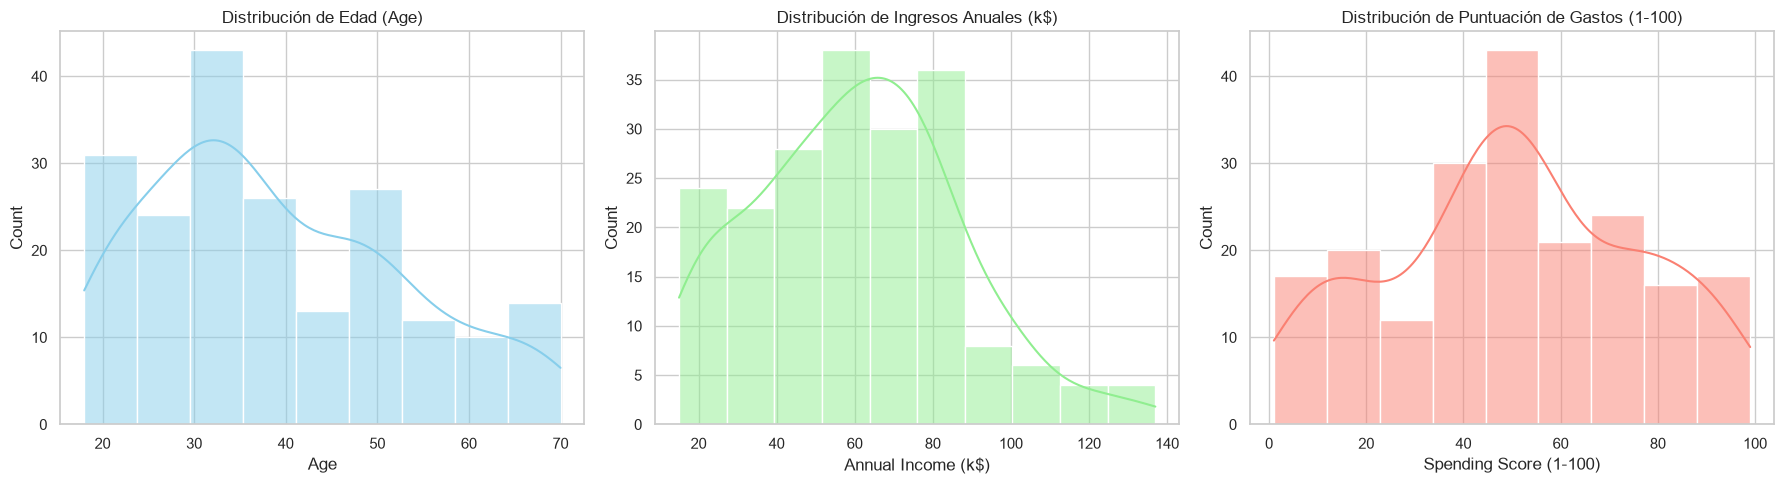

In [6]:
# Visualización de la distribución de las variables numéricas
sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(df['Age'], kde=True, color='skyblue', ax=axes[0])
axes[0].set_title('Distribución de Edad (Age)')

sns.histplot(df['Annual Income (k$)'], kde=True, color='lightgreen', ax=axes[1])
axes[1].set_title('Distribución de Ingresos Anuales (k$)')

sns.histplot(df['Spending Score (1-100)'], kde=True, color='salmon', ax=axes[2])
axes[2].set_title('Distribución de Puntuación de Gastos (1-100)')

plt.tight_layout()
plt.show()

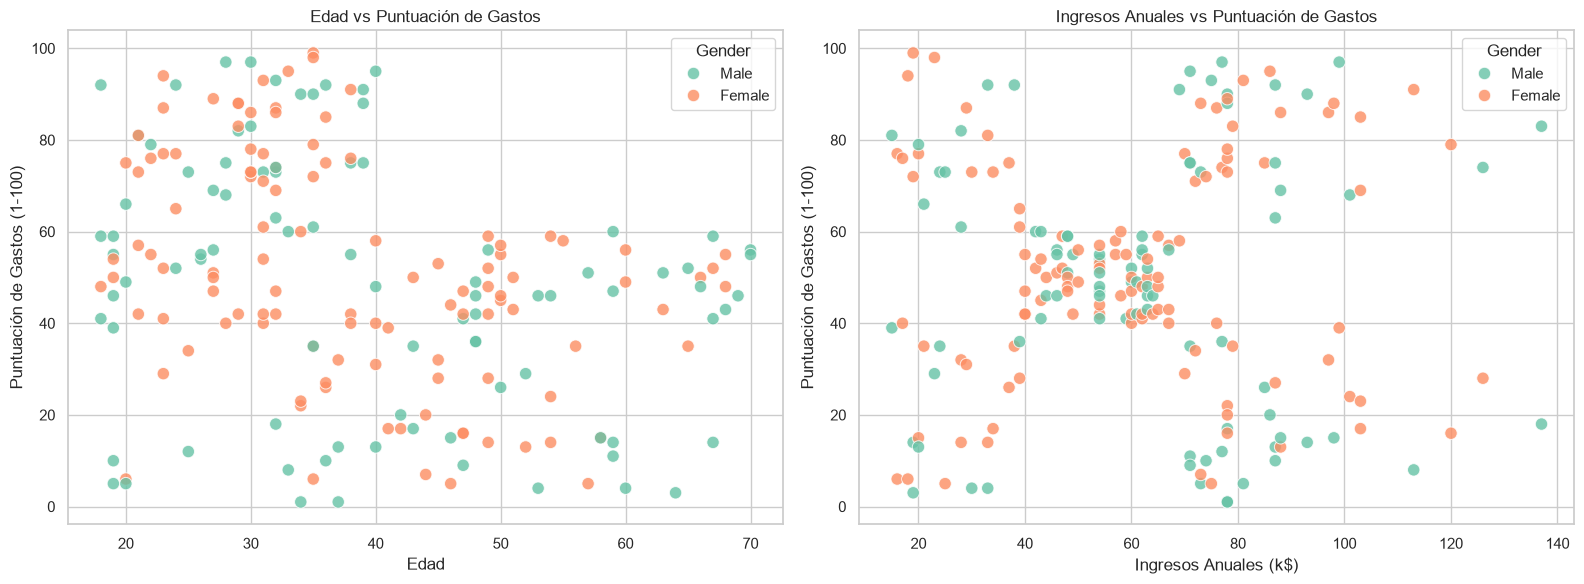

In [7]:
# Gráficos de dispersión para visualizar la relación entre las variables numéricas

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Age vs Spending Score
sns.scatterplot(data=df, x='Age', y='Spending Score (1-100)', 
                hue='Gender', palette='Set2', s=80, alpha=0.8, ax=axes[0])
axes[0].set_title('Edad vs Puntuación de Gastos')
axes[0].set_xlabel('Edad')
axes[0].set_ylabel('Puntuación de Gastos (1-100)')

# Annual Income vs Spending Score
sns.scatterplot(data=df, x='Annual Income (k$)', y='Spending Score (1-100)', 
                hue='Gender', palette='Set2', s=80, alpha=0.8, ax=axes[1])
axes[1].set_title('Ingresos Anuales vs Puntuación de Gastos')
axes[1].set_xlabel('Ingresos Anuales (k$)')
axes[1].set_ylabel('Puntuación de Gastos (1-100)')

plt.tight_layout()
plt.show()

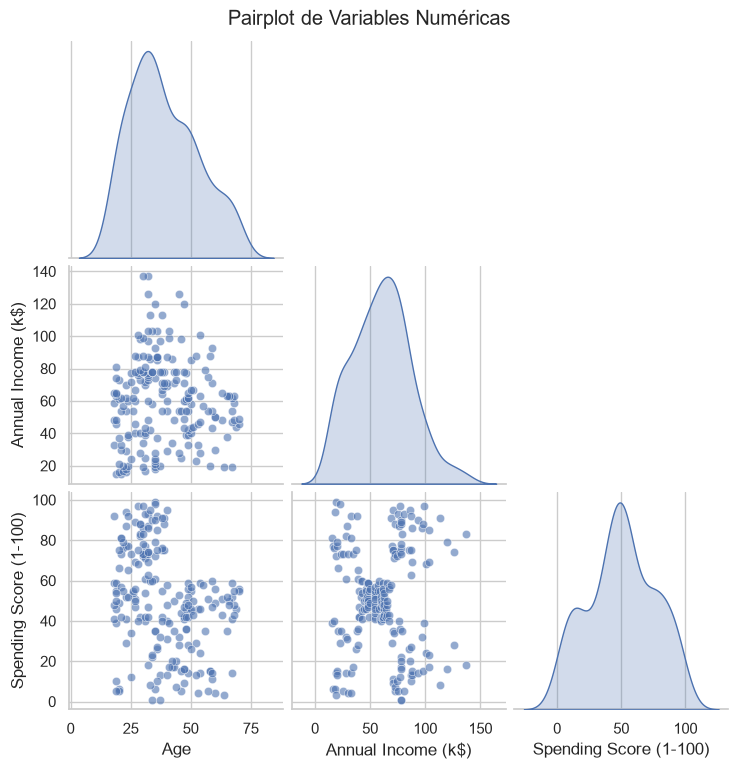

In [8]:
# Gráfico de dispersión general

vars_numericas = ['Age', 'Annual Income (k$)', 'Spending Score (1-100)']
sns.pairplot(df[vars_numericas], diag_kind='kde', corner=True, plot_kws={'alpha': 0.6})
plt.suptitle('Pairplot de Variables Numéricas', y=1.02)
plt.show()

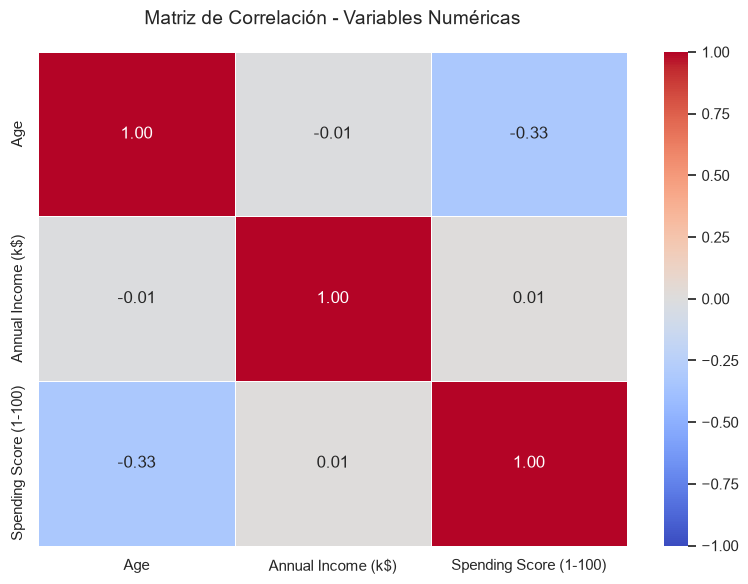

In [ ]:
vars_numericas = ['Age', 'Annual Income (k$)', 'Spending Score (1-100)']
datos_num = df[vars_numericas]

# 2. Calculamos la matriz de correlación (coeficiente de Pearson)
matriz_corr = datos_num.corr()

# 3. Configuramos y renderizamos el mapa de calor
plt.figure(figsize=(8, 6))

sns.heatmap(matriz_corr, 
            annot=True,              # Muestra los coeficientes numéricos exactos
            cmap='coolwarm',         # Rojo para positiva, azul para negativa
            fmt=".2f",               # Redondeo a 2 decimales
            linewidths=0.5,          # Separación entre celdas
            vmin=-1, vmax=1)         # Límites de la escala de Pearson

plt.title('Matriz de Correlación - Variables Numéricas', pad=20, fontsize=14)
plt.tight_layout()
plt.show()

## Limpieza de Datos

In [9]:
df = df.drop(columns=['CustomerID'])  # Eliminamos la columna CustomerID ya que no es relevante para el clustering

df = df.drop(columns=['Gender'])  # Eliminamos la columna Gender ya que es categórica y no se utilizará en el clustering

In [11]:
# Escalado de datos: Método escogido: StandardScaler
from sklearn.preprocessing import StandardScaler
vars_numericas = ['Age', 'Annual Income (k$)', 'Spending Score (1-100)']
datos_para_modelo = df[vars_numericas]

# 2. Instanciar el escalador
scaler = StandardScaler()

# 3. Ajustar y transformar los datos
# fit_transform calcula la media y desviación estándar, y luego aplica la fórmula.
# El resultado 'X' es directamente la matriz numpy consolidada que necesitas.
X = scaler.fit_transform(datos_para_modelo)

# Opcional: Visualizar los primeros registros escalados
df_scaled = pd.DataFrame(X, columns=vars_numericas)
print("Vista de los datos escalados (media ~ 0, varianza = 1):")
print(df_scaled.head())

Vista de los datos escalados (media ~ 0, varianza = 1):
        Age  Annual Income (k$)  Spending Score (1-100)
0 -1.424569           -1.738999               -0.434801
1 -1.281035           -1.738999                1.195704
2 -1.352802           -1.700830               -1.715913
3 -1.137502           -1.700830                1.040418
4 -0.563369           -1.662660               -0.395980
